In [ ]:
%pip -q install scikit-learn pandas matplotlib seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
data = {
    'Outlook': [
        'Sunny', 'Sunny', 'Overcast', 'Rainy', 'Rainy', 'Rainy',
        'Overcast', 'Sunny', 'Sunny', 'Rainy', 'Sunny', 'Overcast',
        'Overcast', 'Rainy', 'Sunny', 'Rainy', 'Overcast', 'Sunny',
        'Rainy', 'Overcast'
    ],
    'Temperature': [
        'Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool',
        'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild',
        'Hot', 'Mild', 'Cool', 'Hot', 'Cool', 'Hot',
        'Cool', 'Mild'
    ],
    'Humidity': [
        'High', 'High', 'High', 'High', 'Normal', 'Normal',
        'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'High', 'High', 'Normal', 'High', 'Normal',
        'High', 'Normal'
    ],
    'Wind': [
        'Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong',
        'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong',
        'Weak', 'Strong', 'Strong', 'Weak', 'Strong', 'Weak',
        'Weak', 'Strong'
    ],
    'Play': [
        'No', 'No', 'Yes', 'Yes', 'Yes', 'No',
        'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'No', 'Yes', 'Yes', 'Yes', 'No',
        'Yes', 'Yes'
    ]
}

df = pd.DataFrame(data)
display(df)
print('Dataset shape:', df.shape)
print(df.head())

,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rainy,Mild,High,Weak,Yes
4,Rainy,Cool,Normal,Weak,Yes
5,Rainy,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rainy,Mild,Normal,Weak,Yes


Dataset shape: (20, 5)


Class distribution:
Play
Yes    14
No      6
Name: count, dtype: int64


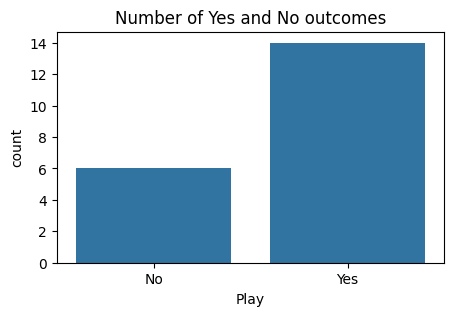


Missing values:
Outlook        0
Temperature    0
Humidity       0
Wind           0
Play           0
dtype: int64


In [3]:
print('Class distribution:')
print(df['Play'].value_counts())

plt.figure(figsize=(5, 3))
sns.countplot(data=df, x='Play')
plt.title('Number of Yes and No outcomes')
plt.show()

print('\nMissing values:')
print(df.isnull().sum())

In [4]:
X = df[['Outlook', 'Temperature', 'Humidity', 'Wind']]
y = df['Play']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

encoders = {}
X_train = pd.DataFrame(index=X_train_raw.index)
X_test = pd.DataFrame(index=X_test_raw.index)

for column in X.columns:
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X_train[column] = encoder.fit_transform(X_train_raw[[column]]).ravel().astype(int)
    X_test[column] = encoder.transform(X_test_raw[[column]]).ravel().astype(int)
    encoders[column] = encoder

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('\nEncoded training features:')
display(X_train.head())

Training rows: 15
Testing rows: 5

Encoded training features:


,Outlook,Temperature,Humidity,Wind
11,0,2,0,0
17,2,1,1,1
16,0,0,0,0
12,0,1,1,1
6,0,0,1,0


In [6]:
category_counts = [df[column].nunique() for column in X.columns]

model = CategoricalNB(alpha=1.0, min_categories=category_counts)
model.fit(X_train, y_train_encoded)

print('Categorical Naive Bayes model trained')

Categorical Naive Bayes model trained


In [7]:
y_pred = model.predict(X_test)

print(f'Accuracy: {accuracy_score(y_test_encoded, y_pred):.2%}')
print('\nClassification report:')
print(classification_report(
    y_test_encoded, y_pred,
    labels=list(range(len(label_encoder.classes_))),
    target_names=label_encoder.classes_,
    zero_division=0
))

Accuracy: 40.00%

Classification report:
              precision    recall  f1-score   support

          No       0.00      0.00      0.00         2
         Yes       0.50      0.67      0.57         3

    accuracy                           0.40         5
   macro avg       0.25      0.33      0.29         5
weighted avg       0.30      0.40      0.34         5



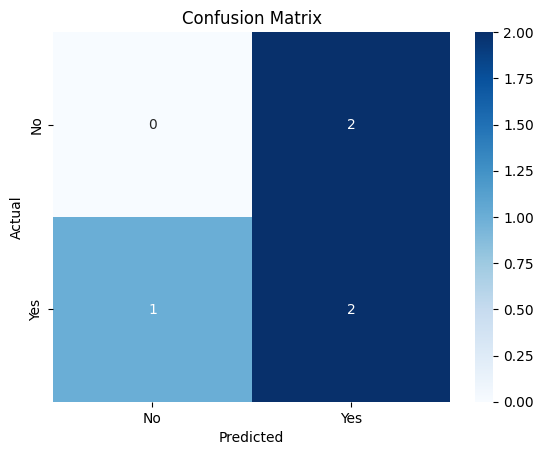

In [8]:
cm = confusion_matrix(
    y_test_encoded, y_pred,
    labels=list(range(len(label_encoder.classes_)))
)

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [9]:
new_weather = pd.DataFrame({
    'Outlook': ['Sunny'],
    'Temperature': ['Cool'],
    'Humidity': ['Normal'],
    'Wind': ['Weak']
})

new_weather_encoded = pd.DataFrame({
    column: encoders[column].transform(new_weather[[column]]).ravel().astype(int)
    for column in X.columns
})

prediction = model.predict(new_weather_encoded)[0]
probabilities = model.predict_proba(new_weather_encoded)[0]
predicted_label = label_encoder.inverse_transform([prediction])[0]

print('New weather condition:')
display(new_weather)
print('Predicted outcome:', predicted_label)
print('\nClass probabilities:')
for class_name, probability in zip(label_encoder.classes_, probabilities):
    print(f'{class_name}: {probability:.2%}')

New weather condition:


,Outlook,Temperature,Humidity,Wind
0,Sunny,Cool,Normal,Weak


Predicted outcome: No

Class probabilities:
No: 50.08%
Yes: 49.92%
